# Cookie Cats: gate_30 or gate_40

Players were randomly assigned to a gate after 30 rounds or after 40 rounds.
`retention_1` means the player came back the day after install.
`retention_7` means the player came back 7 days after install.
`sum_gamerounds` is how many rounds the player played during the measured period.

## 1. Load and first look

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

GATE_30 = "#1F4E5F"
GATE_40 = "#8AA0B2"

def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D9E2EC")
    ax.spines["bottom"].set_color("#D9E2EC")
    ax.tick_params(length=0)
    ax.grid(axis="y", color="#EEF2F6", linewidth=0.8)
    ax.set_axisbelow(True)

def label_bars(ax):
    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=8,
            color="#102A43",
            xytext=(0, 2),
            textcoords="offset points",
        )

df = pd.read_csv("cookie_cats.csv")
df.shape

(90189, 5)

In [2]:
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


90,189 players, one row per player.
`version` is the gate the player was assigned to. It does not mean the player reached that gate.

## 2. Data checks

In [3]:
df.isna().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [4]:
df.dtypes

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

In [5]:
df["userid"].duplicated().sum()

np.int64(0)

In [6]:
df["version"].value_counts()

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

In [7]:
from scipy.stats import chisquare

version_counts = df["version"].value_counts().reindex(["gate_30", "gate_40"])
version_share = (version_counts / version_counts.sum() * 100).round(1)
chi_srm, p_srm = chisquare(version_counts)

print(version_counts.to_string())
print(version_share.to_string())
print("If the planned split was exactly 50/50, p =", round(p_srm, 4))

version
gate_30    44700
gate_40    45489
version
gate_30    49.6
gate_40    50.4
If the planned split was exactly 50/50, p = 0.0086


In [8]:
(df["sum_gamerounds"] < 0).sum()

np.int64(0)

In [9]:
(df["sum_gamerounds"] == 0).sum()

np.int64(3994)

In [10]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [11]:
df.nlargest(5, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


Rounds are capped at 100 in this chart so the player with 49,854 rounds does not squash everyone else into one bar. The dashed lines are the two gates.

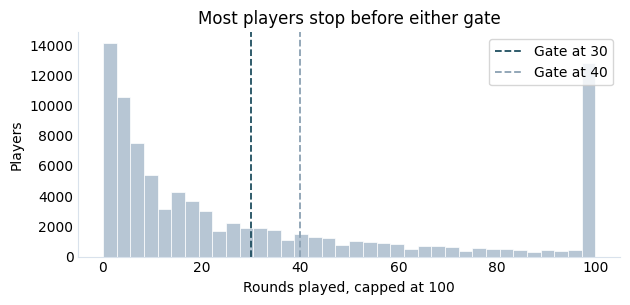

In [12]:
rounds_capped = df["sum_gamerounds"].clip(upper=100)
fig, ax = plt.subplots(figsize=(6.4, 3.15))
ax.hist(rounds_capped, bins=36, color="#B7C6D4", edgecolor="white", linewidth=0.5)
ax.axvline(30, color=GATE_30, linestyle="--", linewidth=1.3, label="Gate at 30")
ax.axvline(40, color=GATE_40, linestyle="--", linewidth=1.3, label="Gate at 40")
ax.set_xlabel("Rounds played, capped at 100")
ax.set_ylabel("Players")
ax.set_title("Most players stop before either gate")
style_axis(ax)
ax.grid(False)
ax.legend()
fig.tight_layout()
plt.show()

Summary of the checks:

- No missing values.
- No duplicate `userid`. Each player appears once.
- The split is close to even: 44,700 players in `gate_30` (49.6%) and 45,489 in `gate_40` (50.4%). The planned allocation is not in this file, so it is unknown whether the gap of 789 players was intended. If the plan was exactly 50/50, the check above gives `p ≈ 0.0086`. With about 90,000 players, a small departure from half and half can reach that p-value. This is a limitation. The retention comparison still uses every assigned player.
- No negative rounds. 3,994 players have 0 rounds: they installed and did not play. That is valid.
- One player played 49,854 rounds, in `gate_30`. Without that player, the average is 51.3 rounds in both versions. The median is 17 rounds in `gate_30` and 16 in `gate_40`. The decision below uses retention, not the average number of rounds.
- There is no column that says "passed the gate". The chart shows that most players are to the left of both gates.

## 3. Analysis

### 3.1 Retention by assigned version

`returned` counts players whose retention value is `True`. `did_not_return` counts players whose retention value is `False`.
A player who did not return on one of these days may still return on another day.
The percentage is the number who returned divided by all players assigned to that version.

,players,returned_day_1,did_not_return_day_1,returned_day_1_pct,returned_day_7,did_not_return_day_7,returned_day_7_pct
version,,,,,,,
gate_30,44700,20034,24666,44.8,8502,36198,19.0
gate_40,45489,20119,25370,44.2,8279,37210,18.2


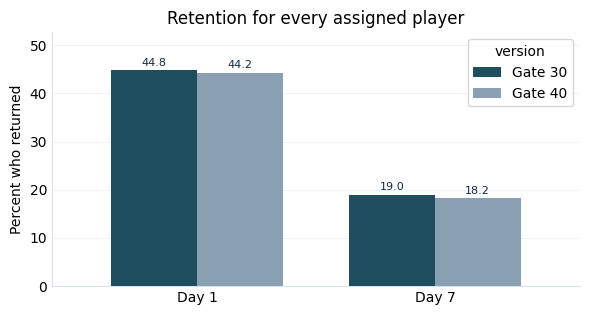

In [13]:
summary = (
    df.groupby("version", sort=False)
    .agg(
        players=("userid", "size"),
        returned_day_1=("retention_1", "sum"),
        returned_day_7=("retention_7", "sum"),
    )
    .reindex(["gate_30", "gate_40"])
)
summary["did_not_return_day_1"] = summary["players"] - summary["returned_day_1"]
summary["did_not_return_day_7"] = summary["players"] - summary["returned_day_7"]
summary["returned_day_1_pct"] = (summary["returned_day_1"] / summary["players"] * 100).round(1)
summary["returned_day_7_pct"] = (summary["returned_day_7"] / summary["players"] * 100).round(1)
summary = summary[
    [
        "players",
        "returned_day_1",
        "did_not_return_day_1",
        "returned_day_1_pct",
        "returned_day_7",
        "did_not_return_day_7",
        "returned_day_7_pct",
    ]
]

from IPython.display import display

display(summary)

fig, ax = plt.subplots(figsize=(6.0, 3.25))
plot_data = summary[["returned_day_1_pct", "returned_day_7_pct"]].T
plot_data.index = ["Day 1", "Day 7"]
plot_data = plot_data.rename(columns={"gate_30": "Gate 30", "gate_40": "Gate 40"})
plot_data.plot(kind="bar", ax=ax, color=[GATE_30, GATE_40], width=0.72, zorder=3)
ax.set_xlabel("")
ax.set_ylabel("Percent who returned")
ax.set_title("Retention for every assigned player")
ax.tick_params(axis="x", rotation=0)
style_axis(ax)
label_bars(ax)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
fig.tight_layout()
plt.show()

After one day, 44.8% returned in `gate_30` and 44.2% returned in `gate_40`.
After a week, 19.0% returned in `gate_30` and 18.2% returned in `gate_40`.

`gate_30` is higher on both measures. The week gap is about 8 extra players returning out of every 1,000. The bars look close because the gap is small. The next section shows the size of each gap, a 95% confidence interval, and a p-value.

### 3.2 Size of the retention difference

The difference is `gate_30` minus `gate_40`, in percentage points.
The 95% confidence interval uses a normal approximation for that difference.
The p-value asks: if the gate truly makes no difference, how often would a gap at least this large show up by chance?

A small p-value means a gap this large would be unusual if the gate made no difference. The interval shows how large the gap is.

In [14]:
import math

from scipy.stats import chi2_contingency, norm

def proportion_difference(success_a, n_a, success_b, n_b):
    p_a = success_a / n_a
    p_b = success_b / n_b
    diff = p_a - p_b
    se = math.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    z = norm.ppf(0.975)
    return diff, diff - z * se, diff + z * se

counts_day_1 = pd.crosstab(df["version"], df["retention_1"])
chi2, p_day_1, dof, expected = chi2_contingency(counts_day_1)

counts_day_7 = pd.crosstab(df["version"], df["retention_7"])
chi2, p_day_7, dof, expected = chi2_contingency(counts_day_7)

diff_day_1, low_day_1, high_day_1 = proportion_difference(
    summary.loc["gate_30", "returned_day_1"],
    summary.loc["gate_30", "players"],
    summary.loc["gate_40", "returned_day_1"],
    summary.loc["gate_40", "players"],
)
diff_day_7, low_day_7, high_day_7 = proportion_difference(
    summary.loc["gate_30", "returned_day_7"],
    summary.loc["gate_30", "players"],
    summary.loc["gate_40", "returned_day_7"],
    summary.loc["gate_40", "players"],
)

print(counts_day_1)
print(
    "day 1: difference",
    round(diff_day_1 * 100, 1),
    "percentage points; 95% CI",
    round(low_day_1 * 100, 1),
    "to",
    round(high_day_1 * 100, 1),
    "; p =",
    round(p_day_1, 4),
)
print(counts_day_7)
print(
    "day 7: difference",
    round(diff_day_7 * 100, 1),
    "percentage points; 95% CI",
    round(low_day_7 * 100, 1),
    "to",
    round(high_day_7 * 100, 1),
    "; p =",
    round(p_day_7, 4),
)

retention_1  False  True 
version                  
gate_30      24666  20034
gate_40      25370  20119
day 1: difference 0.6 percentage points; 95% CI -0.1 to 1.2 ; p = 0.0755
retention_7  False  True 
version                  
gate_30      36198   8502
gate_40      37210   8279
day 7: difference 0.8 percentage points; 95% CI 0.3 to 1.3 ; p = 0.0016


Day 1: `gate_30` is higher by 0.6 percentage points. The 95% interval runs from -0.1 to 1.2 and includes no difference. `p = 0.0755`. The evidence of a day-1 difference is weaker. The direction is the same as day 7.

Day 7: `gate_30` is higher by 0.8 percentage points, about 8 extra players returning out of every 1,000. The 95% interval runs from 0.3 to 1.3. `p = 0.0016`. That is evidence of a week difference in favor of `gate_30`. The gap is still small.

Both days were examined. The recommendation uses day 7, where the difference is clearer. That choice was made after seeing the results.

## 4. Conclusion

On retention, the evidence supports keeping the gate at 30.

The comparison uses every assigned player, because that is the random split. After a week, 19.0% returned in `gate_30` and 18.2% returned in `gate_40`. The difference is 0.8 percentage points in favor of `gate_30`, with a 95% interval from 0.3 to 1.3. `p = 0.0016`. Day 1 points the same way, by 0.6 percentage points, but the day-1 interval includes no difference (`p = 0.0755`), so day 1 alone is not enough.

Both return days were examined. The recommendation uses day 7, where the difference is clearer. That choice was made after seeing the results.

The assigned groups are close to half and half. The planned split is not in the file. The comparison still uses every assigned player.

### A possible explanation

The file shows who came back. It does not show why. One hypothesis to test is that an earlier stop leaves players wanting to come back, so more of them return a week later.

### What to investigate next

- How many players reached the gate, how long they waited, and how much they paid to skip the wait. This file has none of those.
- This file has no purchases or revenue. `gate_40` can keep fewer players and still make more money, or the other way around. If the business goal is money, retention alone cannot decide the move.
- `sum_gamerounds` has one player with 49,854 rounds. If rounds played becomes a metric, look at the median as well as the mean.
- `retention_1` and `retention_7` are counted from the install day, not from the moment the player reached the gate. Measuring "came back after the gate" needs a timestamp of reaching the gate.
- The appendix compares players who reached the same round count. That check does not replace the random assignment, because the gate itself can change how many rounds a player plays.

## Appendix: exploratory engagement analysis

Each table contains only the players assigned to that version who reached the round cutoff.
The `gate_30` table appears first, and the `gate_40` table appears directly below it.
`at_least_30_rounds` includes every player with 30 rounds or more, so players with 40 rounds or more are also in that row.
`at_least_40_rounds` includes only players with 40 rounds or more.

The cutoff is the same number of rounds in both versions. This appendix is a description, separate from the decision in section 4. `sum_gamerounds` is measured after assignment. The gate can change how many rounds a player plays, and coming back to the game can change it too.

,returned_day_7,players,calculation,day_7_pct
cutoff,,,,
at_least_30_rounds,7308,16656,7308 / 16656,43.9
at_least_40_rounds,6822,13566,6822 / 13566,50.3


,returned_day_7,players,calculation,day_7_pct
cutoff,,,,
at_least_30_rounds,7144,16613,7144 / 16613,43.0
at_least_40_rounds,6707,13827,6707 / 13827,48.5


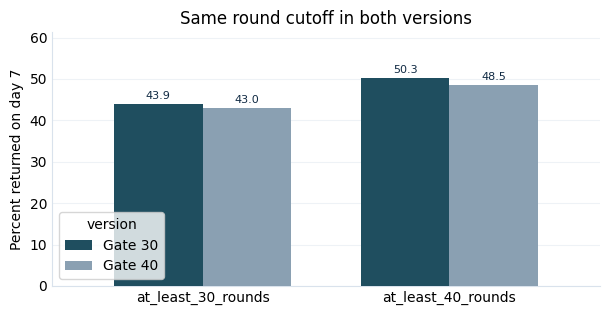

In [15]:
pieces = []
for cutoff, label in [(30, "at_least_30_rounds"), (40, "at_least_40_rounds")]:
    reached = df[df["sum_gamerounds"] >= cutoff]
    part = (
        reached.groupby("version")
        .agg(
            returned_day_7=("retention_7", "sum"),
            players=("userid", "size"),
        )
        .reindex(["gate_30", "gate_40"])
    )
    part["cutoff"] = label
    pieces.append(part)

same_cutoff = pd.concat(pieces).reset_index().set_index(["version", "cutoff"])
same_cutoff["day_7_pct"] = (
    same_cutoff["returned_day_7"] / same_cutoff["players"] * 100
).round(1)
same_cutoff["calculation"] = (
    same_cutoff["returned_day_7"].astype(int).astype(str)
    + " / "
    + same_cutoff["players"].astype(int).astype(str)
)
same_cutoff = same_cutoff[
    ["returned_day_7", "players", "calculation", "day_7_pct"]
]

display(same_cutoff.loc["gate_30"])
display(same_cutoff.loc["gate_40"])

fig, ax = plt.subplots(figsize=(6.2, 3.25))
same_cutoff_plot = (
    same_cutoff["day_7_pct"]
    .unstack(level="version")
    .reindex(columns=["gate_30", "gate_40"])
    .rename(columns={"gate_30": "Gate 30", "gate_40": "Gate 40"})
)
same_cutoff_plot.plot(kind="bar", ax=ax, color=[GATE_30, GATE_40], width=0.72, zorder=3)
ax.set_xlabel("")
ax.set_ylabel("Percent returned on day 7")
ax.set_title("Same round cutoff in both versions")
ax.tick_params(axis="x", rotation=0)
style_axis(ax)
label_bars(ax)
ax.set_ylim(0, ax.get_ylim()[1] * 1.16)
fig.tight_layout()
plt.show()

Same cutoff, both versions, day 7:

- At least 30 rounds: 43.9% in `gate_30`, 43.0% in `gate_40`.
- At least 40 rounds: 50.3% in `gate_30`, 48.5% in `gate_40`.

`gate_30` is higher at both cutoffs. These are players who reached those round counts. The gate itself can change who reaches 30 or 40 rounds.